# Data Preprocessing

Load the images, encode the labels, and split the dataset into training and validation setss

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf



from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

 Before loading images into memory, we'll create a list containing each image's location and its category, We need to connect every image to its correct category before training a classification model.

In [62]:
dataset_path = Path("../data/Waste_Dataset")

image_paths = []
labels = []

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        for image_file in folder.iterdir():
            if image_file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                image_paths.append(str(image_file))
                labels.append(folder.name)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))
print("Categories:", len(set(labels)))

Total images: 4752
Total labels: 4752
Categories: 9


This converts category names into numbers

In [63]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(labels)

print("Category mapping:")

for category, number in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{category}: {number}")

Category mapping:
1-Cardboard: 0
2-Food Organics: 1
3-Glass: 2
4-Metal: 3
5-Miscellaneous Trash: 4
6-Paper: 5
7-Plastic: 6
8-Textile Trash: 7
9-Vegetation: 8


Step 6: Split the dataset
We'll divide the 4,752 images into:
- 80% Training: Used to teach the model.
- 20% Validation: Used to evaluate the model during development.

In [64]:
X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    encoded_labels,
    test_size=0.2,
    random_state=42,
    stratify=encoded_labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

Training images: 3801
Validation images: 951


Our images are 524 × 524. We'll resize them to 224 × 224, which is a common input size for CNN and MobileNet models.


In [65]:
IMG_SIZE = 224

def load_images(paths):
    images = []

    for path in paths:
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        images.append(image)

    return np.array(images)

X_train_images = load_images(X_train)
X_val_images = load_images(X_val)

print("Training shape:", X_train_images.shape)
print("Validation shape:", X_val_images.shape)


Training shape: (3801, 224, 224, 3)
Validation shape: (951, 224, 224, 3)


We need to confirm that the images have three colour channels and that their pixel values are in the expected range.

In [66]:
print("Image shape:", X_train_images[0].shape)
print("Data type:", X_train_images.dtype)
print("Pixel range:", X_train_images.min(), "-", X_train_images.max())

Image shape: (224, 224, 3)
Data type: uint8
Pixel range: 0 - 255


Normalize the images, Smaller consistent input values generally help neural networks train more effectively.

In [67]:
X_train_normalized = X_train_images.astype("float32") / 255.0
X_val_normalized = X_val_images.astype("float32") / 255.0

print("New pixel range:", X_train_normalized.min(), "-", X_train_normalized.max())
print("Data type:", X_train_normalized.dtype)

New pixel range: 0.0 - 1.0
Data type: float32


 verify that the image still looks correct after resizing and normalization.

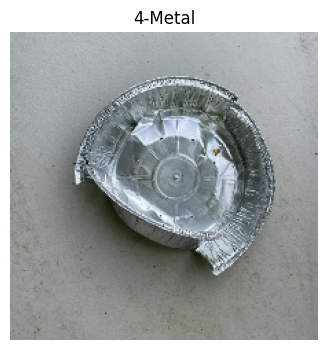

In [68]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train_normalized[0])
plt.title(label_encoder.inverse_transform([y_train[0]])[0])
plt.axis("off")
plt.show()

This function processes one image at a time when the training pipeline requests it, rather than loading the entire dataset into RAM.
Reads images from your dataset.
Converts them into RGB format.
Resizes them to 224 × 224.
Normalizes pixels to 0–1.
Prepares each image and its label for TensorFlow.

In [69]:
IMG_SIZE = 224
BATCH_SIZE = 32

def load_and_preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

### Create TensorFlow Datasets

Prepare training and validation data in batches of 32 images. This allows TensorFlow to load and preprocess images efficiently without loading the entire dataset into memory.

In [70]:
# Create the training dataset from image paths and labels
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

# Apply image preprocessing
train_dataset = train_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle training images to improve learning
train_dataset = train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=42
)

# Group images into batches of 32 and prepare the next batch
train_dataset = train_dataset.batch(BATCH_SIZE)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)


# Create the validation dataset
val_dataset = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

# Apply the same preprocessing without shuffling
val_dataset = val_dataset.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group validation images into batches and prepare them efficiently
val_dataset = val_dataset.batch(BATCH_SIZE)
val_dataset = val_dataset.prefetch(tf.data.AUTOTUNE)

Each batch should contain 32 images.,
Each image should have dimensions 224 × 224 × 3.,
Each image should have a corresponding label.,

Pixel values should be between 0 and 1.

In [71]:
# Get one batch from each dataset
train_images, train_labels = next(iter(train_dataset))
val_images, val_labels = next(iter(val_dataset))

# Check the batch shapes and pixel values
print("Training batch shape:", train_images.shape)
print("Training labels shape:", train_labels.shape)

print("Validation batch shape:", val_images.shape)
print("Validation labels shape:", val_labels.shape)

print("Pixel range:", tf.reduce_min(train_images).numpy(),
      "-", tf.reduce_max(train_images).numpy())

Training batch shape: (32, 224, 224, 3)
Training labels shape: (32,)
Validation batch shape: (32, 224, 224, 3)
Validation labels shape: (32,)
Pixel range: 0.0 - 1.0


### Custom CNN Model

Build a Convolutional Neural Network (CNN) to classify waste images into nine categories.

In [72]:
# Import the layers needed to build our CNN
from tensorflow.keras import layers, models

In [73]:
# Define the input shape for our images
input_shape = (224, 224, 3)

# Create the first convolutional layer
model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv2D(32, (3, 3), activation="relu")
])

# Reduce feature map dimensions while keeping important features using maxpooling
model.add(layers.MaxPooling2D(pool_size=(2, 2)))

Our first convolutional layer detects basic features such as edges and simple textures.

Now we'll add another layers to learn more complex patterns

In [74]:
# Detect more complex image features,layer 2
model.add(layers.Conv2D(64, (3, 3), activation="relu"))

# Reduce the feature map size again
model.add(layers.MaxPooling2D(pool_size=(2, 2)))


# Detect more complex image features,layer 3
model.add(layers.Conv2D(128, (3, 3), activation="relu"))

# Reduce the feature map size again
model.add(layers.MaxPooling2D(pool_size=(2, 2)))


# Convert feature maps into a one-dimensional vector
#Global Average Pooling summarizes the features detected in an image into a smaller list of numbers, same as flattening,
# but it takes the average of each feature map instead of just stacking them
model.add(layers.GlobalAveragePooling2D())


# Learn how to combine the extracted features
#The Dense layer learns how to combine those features to recognize patterns associated with waste categories

model.add(layers.Dense(128, activation="relu"))




# Reduce overfitting by randomly disabling 30% of neurons during each training step.
model.add(layers.Dropout(0.3))


# Final layer that makes the actual classification.
# Classify the image into one of the nine waste categories ,because we have 9 possible outcomes, one for each waste category. 
# The softmax activation function is used to convert the output into a probability distribution over the nine classes
# sum of all probabilities of them should be equal to 1
model.add(layers.Dense(9, activation="softmax"))



# Display the CNN architecture and number of parameters
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,921 (433.29 KB)

 Trainable params: 110,921 (433.29 KB)

 Non-trainable params: 0 (0.00 B)

Compile the CNN
Configure the optimizer, loss function, and evaluation metric before training.

In [75]:
# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Training Callbacks

Prepare callbacks to monitor model performance, stop unnecessary training, and save the best model.

In [76]:
# Stop training if validation loss does not improve
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the best model during training
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="../models/custom_cnn_best.keras",
    monitor="val_loss",
    save_best_only=True
)

Train the Custom CNN
,Train the model using the training dataset and monitor its performance on the validation dataset.

In [77]:
# Train the CNN model
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[early_stopping, model_checkpoint]
)

Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 40s 315ms/step - accuracy: 0.2057 - loss: 2.1297 - val_accuracy: 0.2313 - val_loss: 2.0210
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.2831 - loss: 1.9512 - val_accuracy: 0.3470 - val_loss: 1.7951
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 45s 361ms/step - accuracy: 0.3294 - loss: 1.8102 - val_accuracy: 0.4059 - val_loss: 1.7319
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 52s 423ms/step - accuracy: 0.3815 - loss: 1.7038 - val_accuracy: 0.4532 - val_loss: 1.5930
Epoch 5/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 59s 481ms/step - accuracy: 0.4173 - loss: 1.6166 - val_accuracy: 0.4280 - val_loss: 1.6526
Epoch 6/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 57s 464ms/step - accuracy: 0.4307 - loss: 1.5661 - val_accuracy: 0.4458 - val_loss: 1.5258
Epoch 7/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 59s 478ms/step - accuracy: 0.4686 - loss: 1.4734 - val_accuracy: 0.4974 - val_loss: 1.4063
Epoch 8/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 59s 478ms/step - accuracy: 0.4709 - loss: 1.4

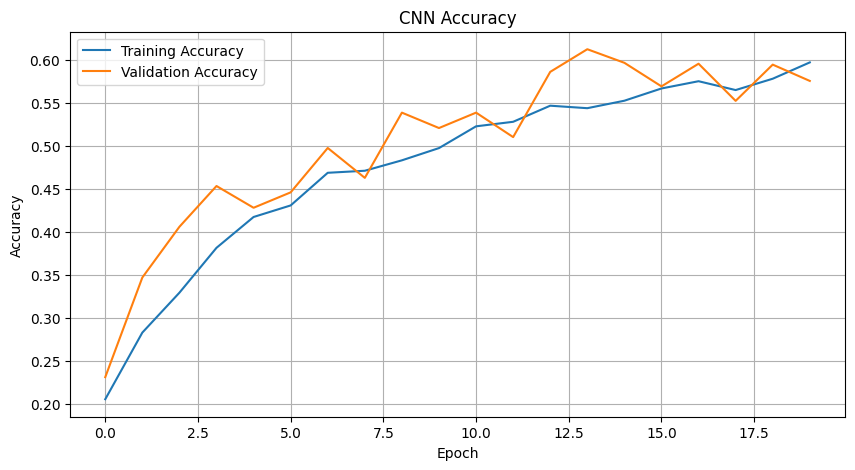

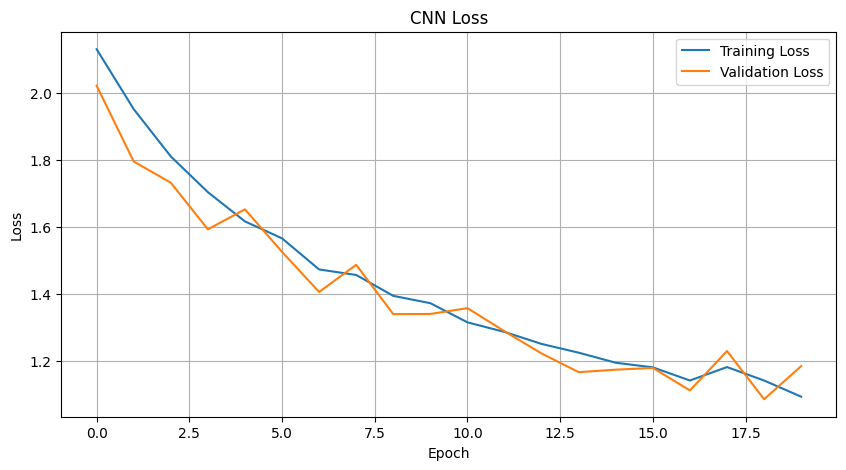

In [78]:
# Plot training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [79]:
print("Epochs completed:", len(history.history["loss"]))

print("Final training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

print("Best validation accuracy:", max(history.history["val_accuracy"]))
print("Best validation loss:", min(history.history["val_loss"]))

print("Best validation loss epoch:",
      np.argmin(history.history["val_loss"]) + 1)

print("Best validation accuracy epoch:",
      np.argmax(history.history["val_accuracy"]) + 1)

Epochs completed: 20
Final training accuracy: 0.5966851115226746
Final validation accuracy: 0.5751839876174927
Final training loss: 1.0942856073379517
Final validation loss: 1.1853965520858765
Best validation accuracy: 0.6119873523712158
Best validation loss: 1.086703896522522
Best validation loss epoch: 19
Best validation accuracy epoch: 14


In [80]:
# Load the model with the best validation loss
best_cnn_model = tf.keras.models.load_model(
    "../models/custom_cnn_best.keras"
)

# Evaluate it on the validation dataset
val_loss, val_accuracy = best_cnn_model.evaluate(val_dataset)

print("Best CNN validation loss:", val_loss)
print("Best CNN validation accuracy:", val_accuracy)

30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 129ms/step - accuracy: 0.5941 - loss: 1.0867
Best CNN validation loss: 1.086703896522522
Best CNN validation accuracy: 0.594111442565918


Classification report.It include Precision, Recall, F1-score.

In [81]:
from sklearn.metrics import classification_report

# Get the true labels from the validation dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in val_dataset
])

# Generate model predictions
y_prob = best_cnn_model.predict(val_dataset)

# Convert probabilities into predicted class numbers
y_pred = np.argmax(y_prob, axis=1)

# Display precision, recall, and F1-score for each category
print(classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 161ms/step
                       precision    recall  f1-score   support

          1-Cardboard       0.63      0.72      0.67        92
      2-Food Organics       0.58      0.79      0.67        82
              3-Glass       0.75      0.51      0.61        84
              4-Metal       0.68      0.56      0.62       158
5-Miscellaneous Trash       0.36      0.23      0.28        99
              6-Paper       0.57      0.52      0.54       100
            7-Plastic       0.55      0.69      0.61       185
      8-Textile Trash       0.45      0.36      0.40        64
         9-Vegetation       0.71      0.87      0.78        87

             accuracy                           0.59       951
            macro avg       0.59      0.58      0.58       951
         weighted avg       0.59      0.59      0.58       951



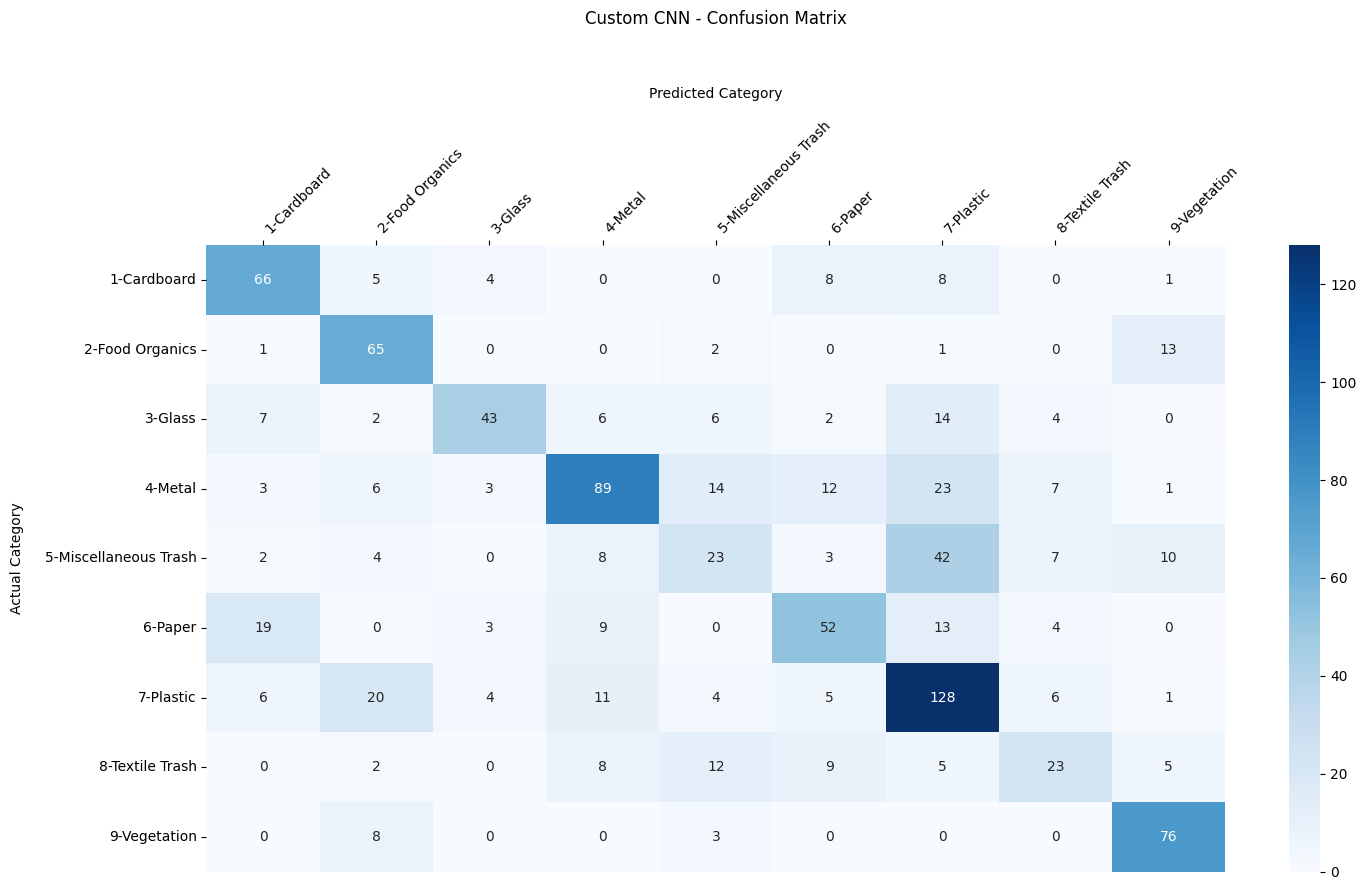

In [82]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(15, 9))

ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

# Move predicted category labels to the top
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

# Add titles and labels
plt.title("Custom CNN - Confusion Matrix", pad=45)
plt.xlabel("Predicted Category", labelpad=15)
plt.ylabel("Actual Category", labelpad=15)

# Adjust label rotation and layout
plt.xticks(rotation=45, ha="left")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "../results/figures/custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Model 2: MobileNetV2 Transfer Learning

In this experiment, we use MobileNetV2 pretrained on ImageNet.
We will adapt it to classify our nine waste categories.

Reads an image from its file path.



Decodes it into RGB format.



Resizes it to 224 × 224.



Scales pixel values to the range MobileNetV2 expects.



Returns the processed image and its label.

In [83]:
import tensorflow as tf

def load_and_preprocess_mobilenet(image_path, label):
    # Read the image from its file path
    image = tf.io.read_file(image_path)

    # Decode the image into RGB format
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])

    # Resize the image to 224x224
    image = tf.image.resize(image, [224, 224])

    # Normalize pixel values to the range [-1, 1] for MobileNetV2
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label

In [84]:
# Create the MobileNetV2 training dataset
mobilenet_train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))

# Apply MobileNetV2 preprocessing to each image
mobilenet_train_dataset = mobilenet_train_dataset.map(
    load_and_preprocess_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Shuffle the training data to improve learning
mobilenet_train_dataset = mobilenet_train_dataset.shuffle(
    buffer_size=len(X_train),
    seed=42
)

# Group images into batches and improve loading performance
mobilenet_train_dataset = mobilenet_train_dataset.batch(BATCH_SIZE)
mobilenet_train_dataset = mobilenet_train_dataset.prefetch(tf.data.AUTOTUNE)


# Create the MobileNetV2 validation dataset
mobilenet_val_dataset = tf.data.Dataset.from_tensor_slices((X_val, y_val))

# Apply the same preprocessing without shuffling
mobilenet_val_dataset = mobilenet_val_dataset.map(
    load_and_preprocess_mobilenet,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Group validation images into batches
mobilenet_val_dataset = mobilenet_val_dataset.batch(BATCH_SIZE)
mobilenet_val_dataset = mobilenet_val_dataset.prefetch(tf.data.AUTOTUNE)



# Check one batch from the training dataset
for images, labels in mobilenet_train_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


### Load pretrained MobileNetV2
MobileNetV2 is already trained on ImageNet, a dataset containing millions of images. We'll reuse its learned visual features instead of learning everything from zero.

In [86]:
# Load MobileNetV2 pretrained on ImageNet
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

# Display the model architecture
base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_4[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [87]:
# Create data augmentation layers
# Introduce small variations in training images to help the model generalize better
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [88]:

# Build the complete MobileNetV2 model
# Define the input layer
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

# Apply data augmentation
x = data_augmentation(inputs)

# Extract image features using pretrained MobileNetV2
x = base_model(x, training=False)

# Reduce the feature maps into a single feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.3)(x)

# Classify images into our nine waste categories
outputs = layers.Dense(9, activation="softmax")(x)

# Create the complete MobileNetV2 model
mobilenet_model = tf.keras.Model(inputs, outputs)

# Display the model architecture
mobilenet_model.summary()

Model: "functional_53"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [91]:
# Compile the MobileNetV2 model
mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Stop training if validation loss stops improving
mobilenet_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Save the model with the best validation loss
mobilenet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="../models/mobilenetv2_best.keras",
    monitor="val_loss",
    save_best_only=True
)


# Train the MobileNetV2 model
mobilenet_history = mobilenet_model.fit(
    mobilenet_train_dataset,
    validation_data=mobilenet_val_dataset,
    epochs=20,
    callbacks=[
        mobilenet_early_stopping,
        mobilenet_checkpoint
    ]
)

Epoch 1/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 62s 453ms/step - accuracy: 0.1800 - loss: 2.3662 - val_accuracy: 0.2713 - val_loss: 1.9430
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 49s 400ms/step - accuracy: 0.3178 - loss: 1.8921 - val_accuracy: 0.4269 - val_loss: 1.5894
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 32s 259ms/step - accuracy: 0.4262 - loss: 1.6136 - val_accuracy: 0.5310 - val_loss: 1.3767
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 57s 452ms/step - accuracy: 0.4978 - loss: 1.4146 - val_accuracy: 0.5720 - val_loss: 1.2415
Epoch 5/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 41s 329ms/step - accuracy: 0.5541 - loss: 1.2850 - val_accuracy: 0.6046 - val_loss: 1.1429
Epoch 6/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 337ms/step - accuracy: 0.5751 - loss: 1.2135 - val_accuracy: 0.6278 - val_loss: 1.0740
Epoch 7/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 334ms/step - accuracy: 0.6122 - loss: 1.1254 - val_accuracy: 0.6456 - val_loss: 1.0278
Epoch 8/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 42s 340ms/step - accuracy: 0.6209 - loss: 1

In [92]:
# Load the best saved MobileNetV2 model
best_mobilenet_model = tf.keras.models.load_model(
    "../models/mobilenetv2_best.keras"
)

# Evaluate the model on the validation dataset
mobilenet_val_loss, mobilenet_val_accuracy = best_mobilenet_model.evaluate(
    mobilenet_val_dataset
)

# Display the evaluation results
print("MobileNetV2 Validation Loss:", mobilenet_val_loss)
print("MobileNetV2 Validation Accuracy:", mobilenet_val_accuracy)


30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 232ms/step - accuracy: 0.7382 - loss: 0.7742
MobileNetV2 Validation Loss: 0.7741827368736267
MobileNetV2 Validation Accuracy: 0.738170325756073


In [93]:
# Get the actual labels from the MobileNetV2 validation dataset
mobilenet_y_true = np.concatenate([
    labels.numpy()
    for images, labels in mobilenet_val_dataset
])

# Generate predictions using the best MobileNetV2 model
mobilenet_y_prob = best_mobilenet_model.predict(mobilenet_val_dataset)

# Convert probabilities into predicted class labels
mobilenet_y_pred = np.argmax(mobilenet_y_prob, axis=1)

# Generate the classification report
# Precision, recall, and F1-score for each category
print(classification_report(
    mobilenet_y_true,
    mobilenet_y_pred,
    target_names=label_encoder.classes_,
    zero_division=0
))

30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 236ms/step
                       precision    recall  f1-score   support

          1-Cardboard       0.83      0.63      0.72        92
      2-Food Organics       0.95      0.63      0.76        82
              3-Glass       0.70      0.74      0.72        84
              4-Metal       0.83      0.76      0.79       158
5-Miscellaneous Trash       0.53      0.47      0.50        99
              6-Paper       0.70      0.81      0.75       100
            7-Plastic       0.70      0.81      0.75       185
      8-Textile Trash       0.71      0.70      0.71        64
         9-Vegetation       0.78      1.00      0.88        87

             accuracy                           0.74       951
            macro avg       0.75      0.73      0.73       951
         weighted avg       0.75      0.74      0.74       951



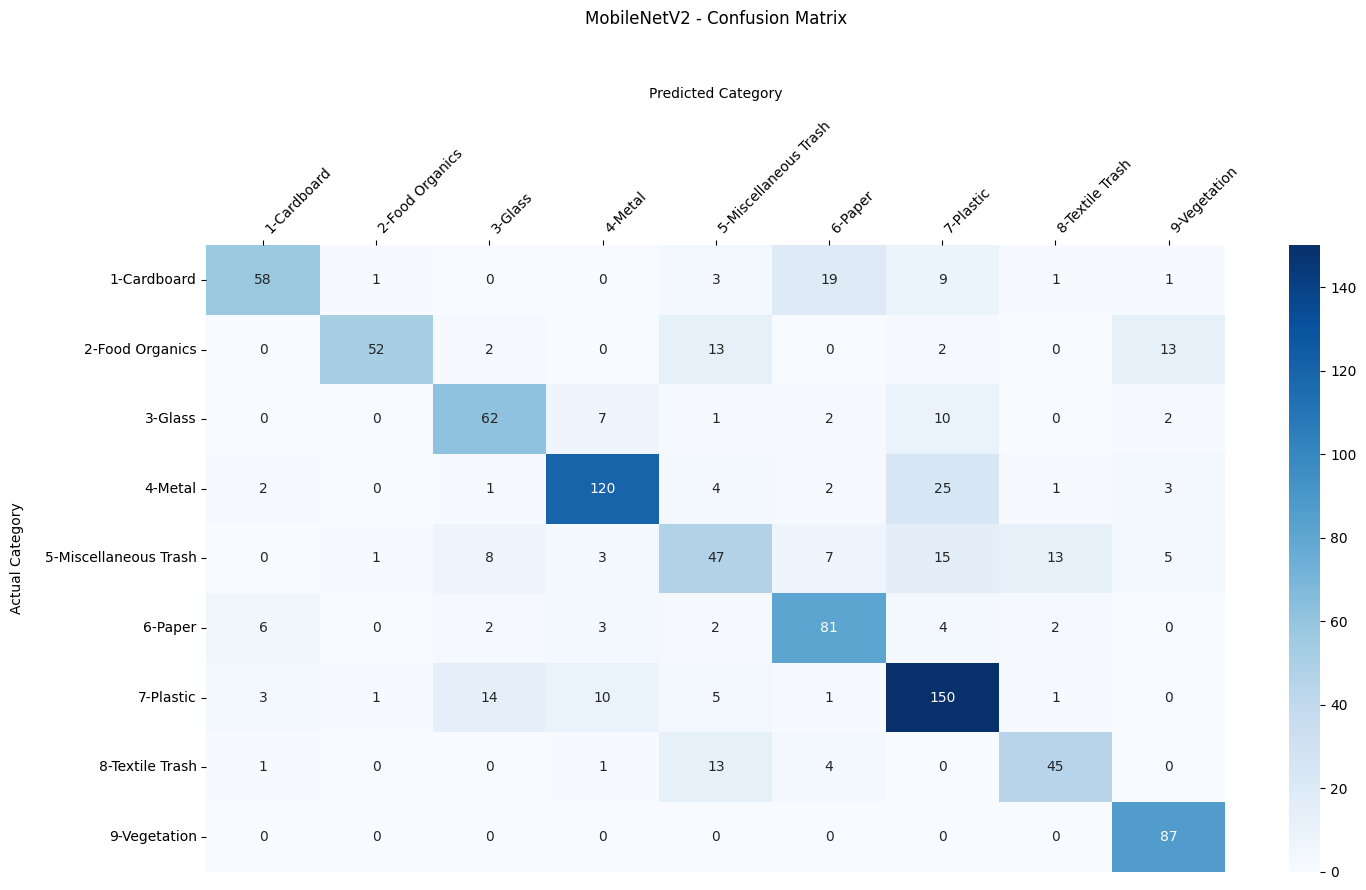

In [95]:
# Calculate the MobileNetV2 confusion matrix
mobilenet_cm = confusion_matrix(
    mobilenet_y_true,
    mobilenet_y_pred
)

# Plot the confusion matrix
plt.figure(figsize=(15, 9))

ax = sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

# Place predicted categories at the top
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")

plt.title("MobileNetV2 - Confusion Matrix", pad=45)
plt.xlabel("Predicted Category", labelpad=15)
plt.ylabel("Actual Category", labelpad=15)
plt.xticks(rotation=45, ha="left")
plt.yticks(rotation=0)
plt.tight_layout()

# Save the confusion matrix
plt.savefig(
    "../results/figures/mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [96]:
# Display the confusion matrix as a readable table
mobilenet_cm_df = pd.DataFrame(
    mobilenet_cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

display(mobilenet_cm_df)

,1-Cardboard,2-Food Organics,3-Glass,4-Metal,5-Miscellaneous Trash,6-Paper,7-Plastic,8-Textile Trash,9-Vegetation
1-Cardboard,58,1,0,0,3,19,9,1,1
2-Food Organics,0,52,2,0,13,0,2,0,13
3-Glass,0,0,62,7,1,2,10,0,2
4-Metal,2,0,1,120,4,2,25,1,3
5-Miscellaneous Trash,0,1,8,3,47,7,15,13,5
6-Paper,6,0,2,3,2,81,4,2,0
7-Plastic,3,1,14,10,5,1,150,1,0
8-Textile Trash,1,0,0,1,13,4,0,45,0
9-Vegetation,0,0,0,0,0,0,0,0,87


#### we want to use the trained model on a new image.

In [97]:
# Load the best saved MobileNetV2 model
best_mobilenet_model = tf.keras.models.load_model(
    "../models/mobilenetv2_best.keras"
)


# Define a function to predict the waste category of one image
def predict_waste_image(image_path):

    # Read the image
    image = tf.io.read_file(image_path)

    # Decode the image into RGB format
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Resize the image to 224x224
    image = tf.image.resize(image, [224, 224])

    # Apply MobileNetV2 preprocessing
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    # Add a batch dimension because the model expects batches of images
    image = tf.expand_dims(image, axis=0)

    # Predict probabilities for the nine categories
    probabilities = best_mobilenet_model.predict(image, verbose=0)[0]

    # Find the category with the highest probability
    predicted_index = np.argmax(probabilities)

    # Get the category name
    predicted_category = label_encoder.classes_[predicted_index]

    # Get the prediction confidence
    confidence = probabilities[predicted_index] * 100

    return predicted_category, confidence

#### TEST IT 


In [98]:
# Select one image from the validation dataset
test_image_path = X_val[0]

# Predict its waste category
predicted_category, confidence = predict_waste_image(test_image_path)

print("Predicted Category:", predicted_category)
print(f"Confidence: {confidence:.2f}%")

Predicted Category: 4-Metal
Confidence: 91.23%


This cell will display the original image, its predicted category, confidence, and probabilities for all nine classes.

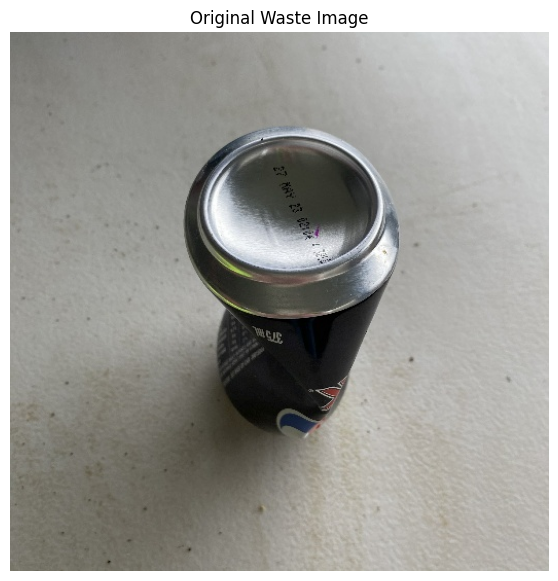

Predicted Category: 4-Metal
Confidence: 91.33%


,Category,Probability (%)
3,4-Metal,91.330002
2,3-Glass,4.520000
6,7-Plastic,2.370000
4,5-Miscellaneous Trash,1.320000
0,1-Cardboard,0.180000
5,6-Paper,0.130000
7,8-Textile Trash,0.080000
8,9-Vegetation,0.050000
1,2-Food Organics,0.010000


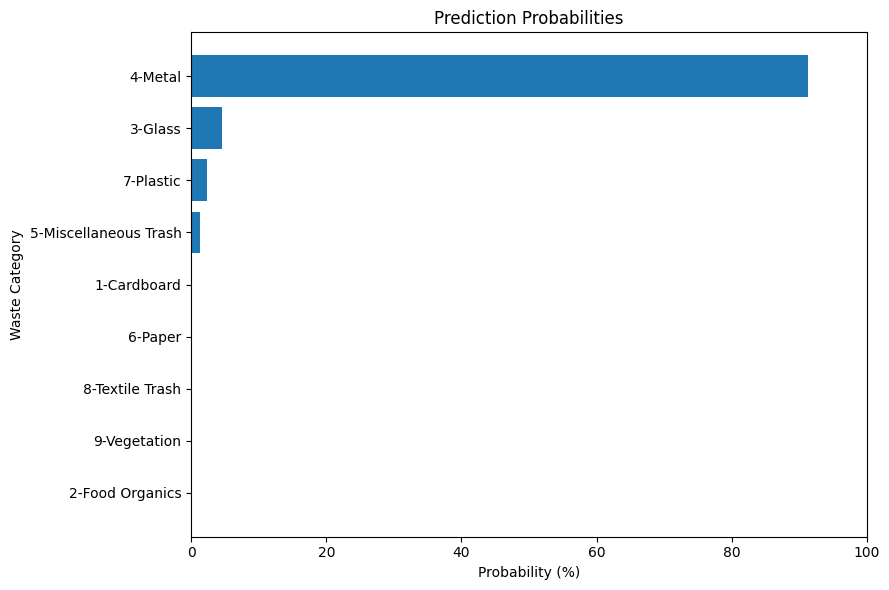

In [105]:
# Read the original image directly from its file path
original_image = cv2.imread(str(test_image_path))

# Check that the image was loaded successfully
if original_image is None:
    raise FileNotFoundError(f"Could not load image: {test_image_path}")

# Convert BGR to RGB
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)


# Display the original image separately
plt.figure(figsize=(7, 7))
plt.imshow(original_image)
plt.title("Original Waste Image")
plt.axis("off")
plt.show()


# Display prediction results
print("Predicted Category:", predicted_category)
print(f"Confidence: {confidence:.2f}%")


# Display all nine category probabilities
display(probability_df.round(2))


# Display prediction probability chart separately
plt.figure(figsize=(9, 6))

plt.barh(
    probability_df["Category"],
    probability_df["Probability (%)"]
)

plt.xlabel("Probability (%)")
plt.ylabel("Waste Category")
plt.title("Prediction Probabilities")

plt.xlim(0, 100)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Model Comparison

Two models were trained and evaluated using the same validation dataset:

1. Custom CNN
2. MobileNetV2 Transfer Learning

MobileNetV2 achieved better validation accuracy, lower validation loss, and a higher macro F1-score.

Therefore, MobileNetV2 is selected as the best-performing model.

In [106]:
# Compare the performance of both models

comparison_df = pd.DataFrame({
    "Metric": [
        "Validation Accuracy",
        "Validation Loss",
        "Macro F1-Score"
    ],
    "Custom CNN": [
        0.5941,
        1.0867,
        0.58
    ],
    "MobileNetV2": [
        0.7382,
        0.7742,
        0.73
    ]
})

display(comparison_df.round(4))

,Metric,Custom CNN,MobileNetV2
0,Validation Accuracy,0.5941,0.7382
1,Validation Loss,1.0867,0.7742
2,Macro F1-Score,0.5800,0.7300


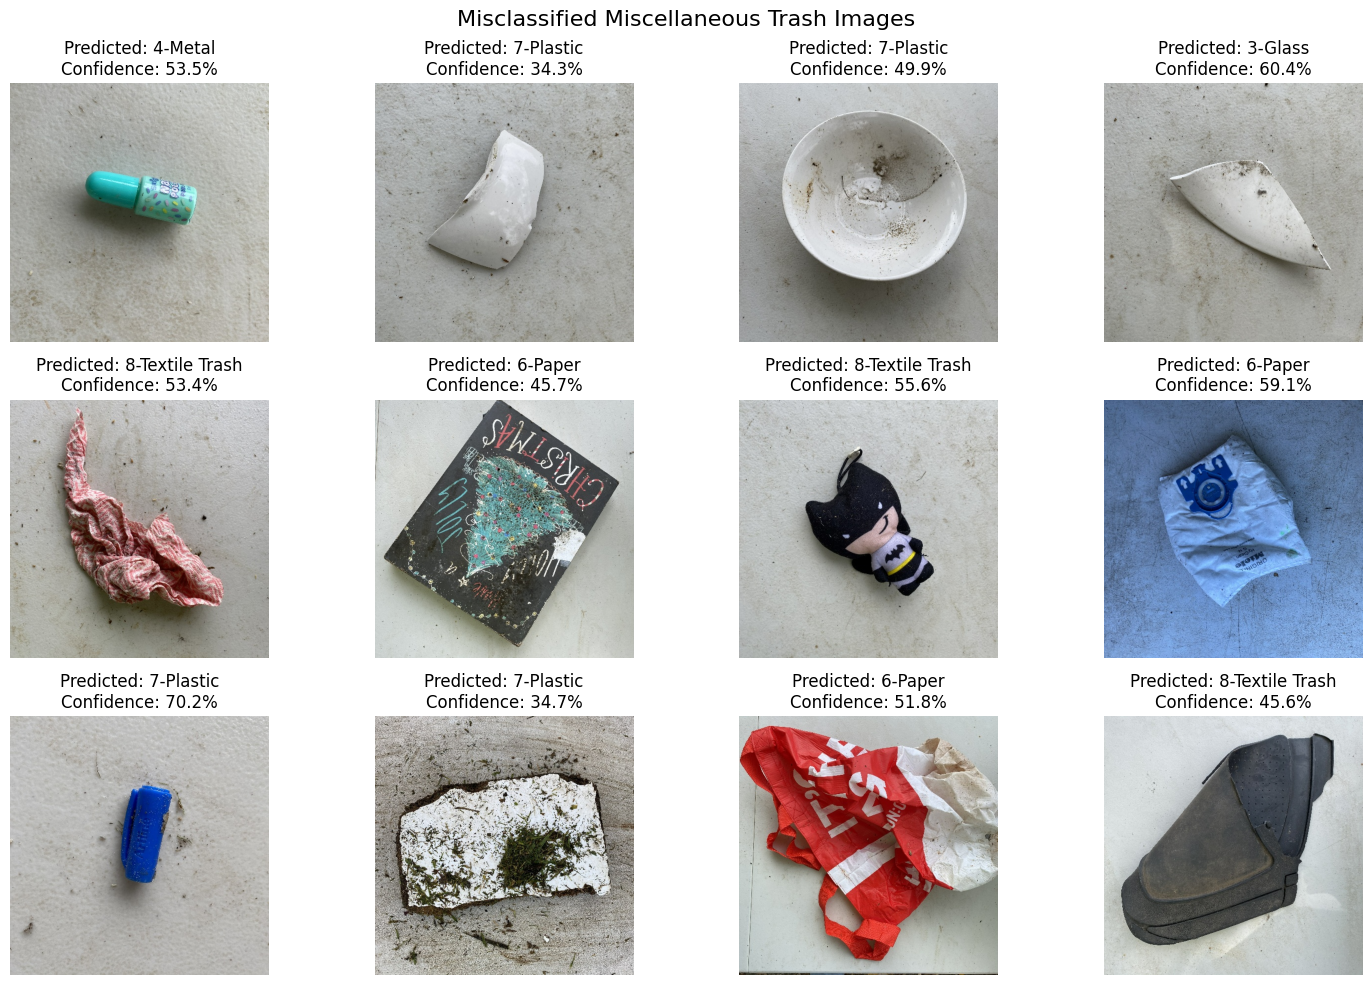

In [107]:
# Find the index of Miscellaneous Trash
misc_index = np.where(
    label_encoder.classes_ == "5-Miscellaneous Trash"
)[0][0]

# Find images that actually belong to Miscellaneous Trash
# but were classified incorrectly
misclassified_indices = np.where(
    (mobilenet_y_true == misc_index) &
    (mobilenet_y_pred != misc_index)
)[0]

# Select up to 12 images to inspect
selected_indices = misclassified_indices[:12]

# Display the misclassified images
plt.figure(figsize=(15, 10))

for position, index in enumerate(selected_indices):

    # Read the original image
    image = cv2.imread(str(X_val[index]))

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Get the predicted category
    predicted_category = label_encoder.classes_[
        mobilenet_y_pred[index]
    ]

    # Get prediction confidence
    confidence = mobilenet_y_prob[index][
        mobilenet_y_pred[index]
    ] * 100

    # Display image
    plt.subplot(3, 4, position + 1)
    plt.imshow(image)

    plt.title(
        f"Predicted: {predicted_category}\n"
        f"Confidence: {confidence:.1f}%"
    )

    plt.axis("off")

plt.suptitle(
    "Misclassified Miscellaneous Trash Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

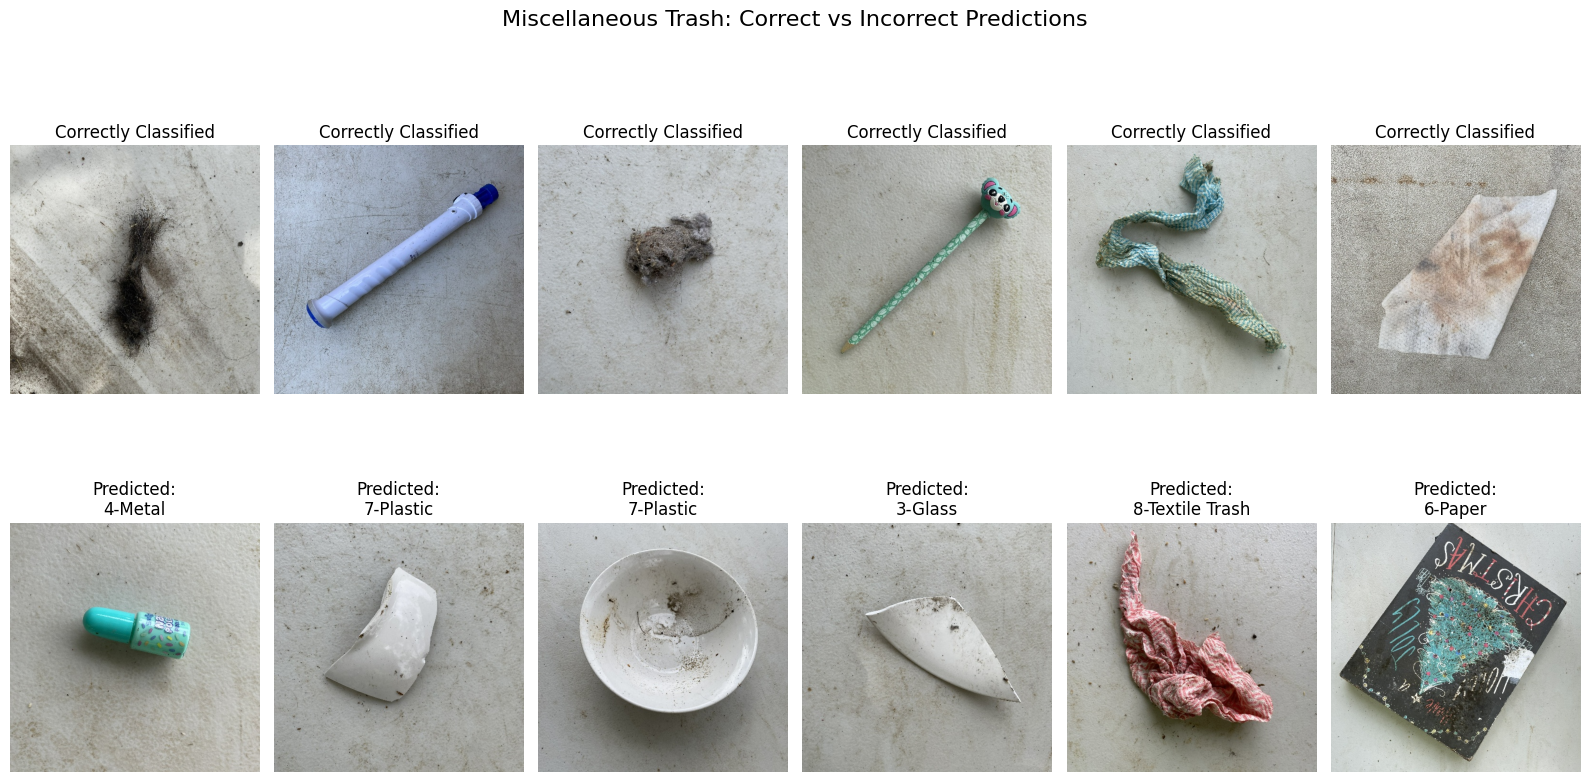

In [108]:
# Find correctly classified Miscellaneous Trash images
correct_indices = np.where(
    (mobilenet_y_true == misc_index) &
    (mobilenet_y_pred == misc_index)
)[0]

# Find incorrectly classified Miscellaneous Trash images
incorrect_indices = np.where(
    (mobilenet_y_true == misc_index) &
    (mobilenet_y_pred != misc_index)
)[0]

# Select 6 images from each group
selected_correct = correct_indices[:6]
selected_incorrect = incorrect_indices[:6]

# Create a comparison visualization
plt.figure(figsize=(16, 9))

# Display correctly classified images
for i, index in enumerate(selected_correct):

    image = cv2.imread(str(X_val[index]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 6, i + 1)
    plt.imshow(image)
    plt.title("Correctly Classified")
    plt.axis("off")


# Display incorrectly classified images
for i, index in enumerate(selected_incorrect):

    image = cv2.imread(str(X_val[index]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    predicted_category = label_encoder.classes_[
        mobilenet_y_pred[index]
    ]

    plt.subplot(2, 6, i + 7)
    plt.imshow(image)
    plt.title(f"Predicted:\n{predicted_category}")
    plt.axis("off")


plt.suptitle(
    "Miscellaneous Trash: Correct vs Incorrect Predictions",
    fontsize=16
)

plt.tight_layout()
plt.show()

,Category,Precision,Recall,F1-Score,Support
0,1-Cardboard,0.829,0.630,0.716,92
1,2-Food Organics,0.945,0.634,0.759,82
2,3-Glass,0.697,0.738,0.717,84
3,4-Metal,0.833,0.759,0.795,158
4,5-Miscellaneous Trash,0.534,0.475,0.503,99
5,6-Paper,0.698,0.810,0.750,100
6,7-Plastic,0.698,0.811,0.750,185
7,8-Textile Trash,0.714,0.703,0.709,64
8,9-Vegetation,0.784,1.000,0.879,87


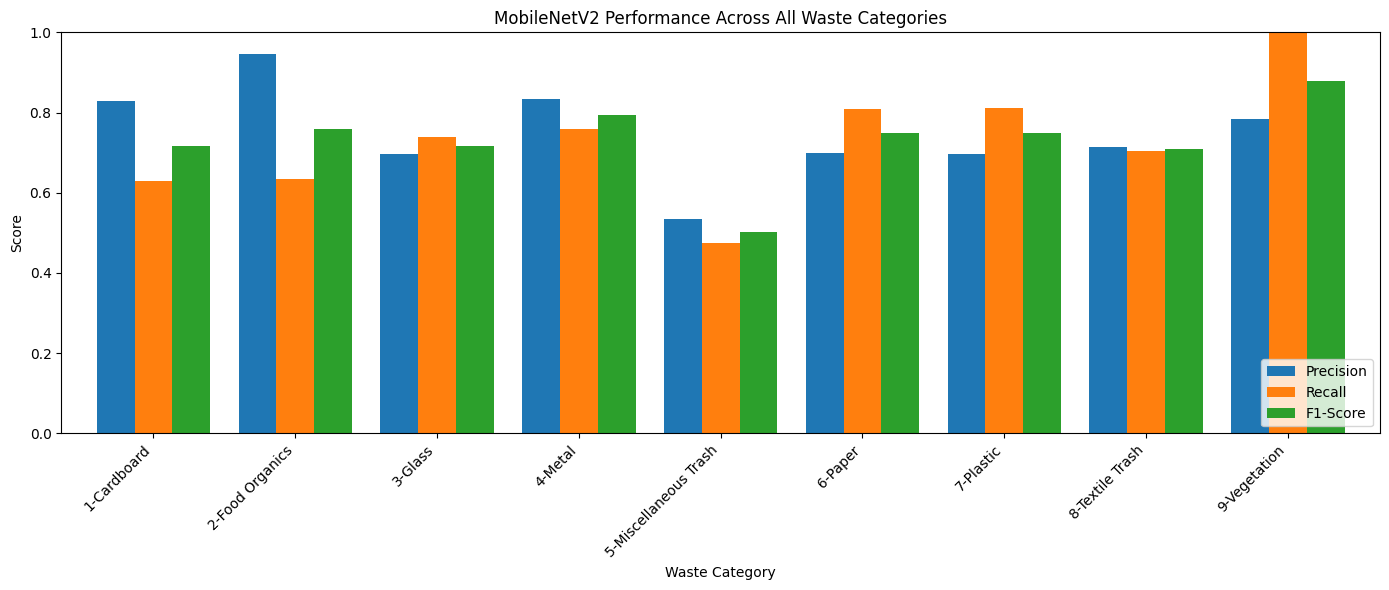

In [109]:
# Calculate precision, recall, and F1-score for all categories
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1_score, support = precision_recall_fscore_support(
    mobilenet_y_true,
    mobilenet_y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    zero_division=0
)

# Create a DataFrame containing the results
class_performance_df = pd.DataFrame({
    "Category": label_encoder.classes_,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1_score,
    "Support": support
})

# Display the performance table
display(class_performance_df.round(3))


# Visualize the performance of all nine categories
class_performance_df.set_index("Category")[
    ["Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(14, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("MobileNetV2 Performance Across All Waste Categories")
plt.xlabel("Waste Category")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Final Model Evaluation

### 1. Model Comparison

Two deep learning models were developed and evaluated using the same validation dataset:

- Custom CNN
- MobileNetV2 Transfer Learning

MobileNetV2 achieved better performance than the Custom CNN.

| Metric | Custom CNN | MobileNetV2 |
|---|---:|---:|
| Validation Accuracy | 59.41% | 73.82% |
| Validation Loss | 1.0867 | 0.7742 |
| Macro F1-Score | 0.58 | 0.73 |

MobileNetV2 improved validation accuracy by 14.41 percentage points.

### 2. Category-Level Performance

MobileNetV2 achieved different performance levels across the nine waste categories.

- Best-performing category: Vegetation (F1-score: 0.88).
- Weakest-performing category: Miscellaneous Trash (F1-score: 0.50).

The model showed difficulty distinguishing some Miscellaneous Trash images from other waste categories.

### 3. Error Analysis

The confusion matrix and misclassified image visualizations were used to investigate classification errors.

The analysis showed that the model sometimes confused Miscellaneous Trash with Metal, Plastic, Glass, Textile Trash, and Paper.

### 4. Limitations

- The dataset contained 4,752 images.
- The dataset was divided into 3,801 training images and 951 validation images.
- No independent test dataset was available during this evaluation.
- Therefore, the reported accuracy represents validation performance rather than independent test performance.

### 5. Conclusion

MobileNetV2 was selected as the best-performing model because it achieved higher validation accuracy and a better macro F1-score than the Custom CNN.

Further improvements could include investigating class imbalance, improving the representation of difficult categories, and evaluating the final model using an independent test dataset.